## Task
###  How dimensionality reduction using Principal Component Analysis (PCA) on the Wine Quality dataset contributes to improving the classification accuracy and efficiency of wine type.
###  Note : Use KNN for Classification.

In [24]:
import numpy as np
import pandas as pd

In [25]:
df=pd.read_csv(r'C:\COLLEGE DATA\College profile\Machine Learning\ML_Practice_with_python_code\Datasets\winequalityN - winequalityN.csv')
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [26]:
df.shape

(6497, 13)

In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   str    
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [28]:
df.isnull().sum()

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

In [29]:
df.duplicated().sum()

np.int64(1168)

In [30]:
# We need to remove duplicated rows and missing value rows
df.dropna().shape

(6463, 13)

In [31]:
# Dropping Duplicates rows
df.drop_duplicates(inplace=True)
print("Wine Data Shape (After Dropping-) :", df.shape)

Wine Data Shape (After Dropping-) : (5329, 13)


In [35]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

### Best solution: Imputation

Before scaling, fill the missing values.

For numerical features, a common approach is median imputation:

## Find KNN Without PCA

In [36]:
# Separate features (physicochemical properties) and target variable (type)
X = df.drop('type', axis=1)
y = df['type']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [37]:
# Train a K-Nearest Neighbors (KNN) classifier without PCA
knn_no_pca = KNeighborsClassifier(n_neighbors=5)
knn_no_pca.fit(X_train_scaled, y_train)

# Predict the wine type on the testing set without PCA
y_pred_no_pca = knn_no_pca.predict(X_test_scaled)

# Evaluate the classification accuracy without PCA
accuracy_no_pca = accuracy_score(y_test, y_pred_no_pca)
print("KNN having features -", X_train_scaled.shape[1])
print("Classification Accuracy without PCA: {:.2f}%".format(accuracy_no_pca * 100))

KNN having features - 12
Classification Accuracy without PCA: 99.16%


## Find KNN With PCA

In [38]:
# Apply PCA on the standardized features
pca = PCA(n_components=5) # no.of best features
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Train a K-Nearest Neighbors (KNN) classifier with PCA
knn_with_pca = KNeighborsClassifier(n_neighbors=5)
knn_with_pca.fit(X_train_pca, y_train)

# Predict the wine type on the testing set with PCA
y_pred_pca = knn_with_pca.predict(X_test_pca)

# Evaluate the classification accuracy with PCA
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print("KNN having features -", X_train_pca.shape[1])
print("Classification Accuracy with PCA: {:.2f}%".format(accuracy_pca * 100))

KNN having features - 5
Classification Accuracy with PCA: 98.69%


In [41]:
for i in range(1,13):
    # Apply PCA on the standardized features
    pca = PCA(n_components=i) # no.of best features
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    # Train a K-Nearest Neighbors (KNN) classifier with PCA
    knn_with_pca = KNeighborsClassifier(n_neighbors=5)
    knn_with_pca.fit(X_train_pca, y_train)

    # Predict the wine type on the testing set with PCA
    y_pred_pca = knn_with_pca.predict(X_test_pca)

    # Evaluate the classification accuracy with PCA
    accuracy_pca = accuracy_score(y_test, y_pred_pca)

    print("KNN having features -", X_train_pca.shape[1])
    print("Classification Accuracy with PCA: {:.2f}%".format(accuracy_pca * 100))


KNN having features - 1
Classification Accuracy with PCA: 97.56%
KNN having features - 2
Classification Accuracy with PCA: 97.94%
KNN having features - 3
Classification Accuracy with PCA: 97.84%
KNN having features - 4
Classification Accuracy with PCA: 98.59%
KNN having features - 5
Classification Accuracy with PCA: 98.69%
KNN having features - 6
Classification Accuracy with PCA: 98.97%
KNN having features - 7
Classification Accuracy with PCA: 98.97%
KNN having features - 8
Classification Accuracy with PCA: 98.87%
KNN having features - 9
Classification Accuracy with PCA: 99.06%
KNN having features - 10
Classification Accuracy with PCA: 99.16%
KNN having features - 11
Classification Accuracy with PCA: 99.06%
KNN having features - 12
Classification Accuracy with PCA: 99.16%


### PCA Key Features

In [46]:
# no.of eigen vectors
pca.components_

array([[-2.94908135e-01, -4.01900488e-01,  1.19070695e-01,
         2.54435676e-01, -3.45264968e-01,  4.13450340e-01,
         4.48044345e-01, -1.91124824e-01, -1.62691541e-01,
        -3.17476449e-01,  3.19677604e-02,  1.29948298e-01],
       [ 2.14138894e-01,  4.06995380e-02,  1.72769448e-01,
         3.90187798e-01,  2.12652293e-01,  1.90139450e-01,
         2.28929048e-01,  5.23645824e-01, -1.78576154e-01,
         7.39228494e-02, -4.89644406e-01, -2.92060167e-01],
       [ 4.52283062e-01, -2.82395063e-01,  5.87211974e-01,
        -8.57891599e-02,  7.65516358e-02, -7.18968929e-02,
        -9.00193463e-02, -6.17073403e-02, -4.19057723e-01,
         1.79077452e-01,  2.14420068e-01,  2.94823180e-01],
       [-1.53216343e-01, -5.06774760e-02,  5.23430660e-02,
         1.61359088e-01,  1.74819254e-01,  2.79546031e-01,
         1.13727386e-01,  1.67783621e-01,  4.82567621e-01,
         5.54391642e-01,  1.06031089e-01,  4.93885395e-01],
       [ 2.51605430e-01,  1.92070944e-01, -1.6073783

In [48]:
# no.of eigen values = 12 features =12 e.values
pca.explained_variance_

array([3.03653009, 2.63560022, 1.67479753, 1.0753157 , 0.8377017 ,
       0.66730537, 0.53852975, 0.50085093, 0.47489716, 0.30234478,
       0.22371094, 0.03523141])

In [49]:
# % ratio of each eigen values
pca.explained_variance_ratio_

array([0.25298482, 0.21958183, 0.13953372, 0.08958862, 0.0697921 ,
       0.05559574, 0.04486695, 0.04172779, 0.03956548, 0.02518949,
       0.01863821, 0.00293526])

In [50]:
np.cumsum(pca.explained_variance_ratio_)

array([0.25298482, 0.47256665, 0.61210037, 0.70168899, 0.77148109,
       0.82707683, 0.87194378, 0.91367156, 0.95323704, 0.97842653,
       0.99706474, 1.        ])

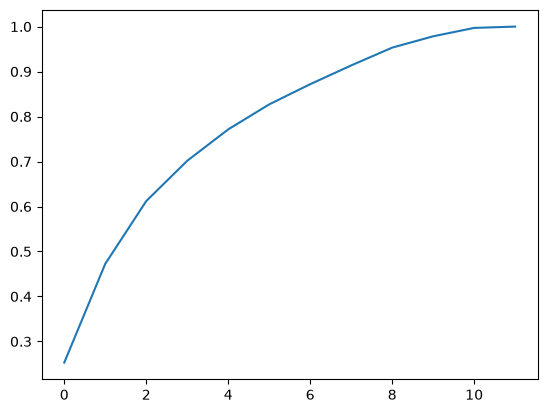

In [51]:
import matplotlib.pyplot as plt

plt.plot(np.cumsum(pca.explained_variance_ratio_))

### So what is "best variance"?

Usually, we choose the number of PCs that retains a sufficiently high cumulative explained variance, 
commonly around 90–95% depending on the problem.
So here is best varaince features till 8 columns

### Important: 
The largest eigenvalue gives the highest-variance direction (PC1). We don't simply choose the largest variance and stop; we decide how many components to keep based on how much total variance we want to retain.

### Why need PCA ?
PCA is used for dimensionality reduction: it transforms many possibly correlated features into fewer uncorrelated principal components while retaining maximum possible variance (information).